# Grupo 7 · Clasificación de consumo energético con sensores IoT

**Curso:** Machine Learning (UNI-FIIS) · **Profesor:** Dr. Ing. Hilario Aradiel Castañeda · **Ciclo:** 2026-II
**Integrantes:** Crisostomo Cahuas, Gabriel Andre (20240090I) · Curto Meneses, Alessandro del Piero (20242084F) · Rubio Zeta, Luis Miguel (202210132K)

Este cuaderno tiene el mismo código que `main.py`, dividido por pasos de CRISP-ML(Q), y muestra las tablas y figuras dentro del cuaderno.
Los datos (`datos_grupo7.csv`) se captaron con un ESP32 y un sensor INA219 (ver `captura_grupo7.ino` y `capturar.py`).

## Paso 0. Importación de librerías

In [1]:
import warnings
from IPython.display import display
from pathlib import Path

import matplotlib
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import kurtosis, skew
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.ensemble import (AdaBoostClassifier, ExtraTreesClassifier,
                              GradientBoostingClassifier, HistGradientBoostingClassifier,
                              RandomForestClassifier)
from sklearn.feature_selection import mutual_info_classif
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, confusion_matrix,
                             f1_score, log_loss)
from sklearn.base import clone
from sklearn.model_selection import GridSearchCV, StratifiedGroupKFold, train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC, LinearSVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.tree import DecisionTreeClassifier

warnings.filterwarnings("ignore")

## Paso 0.1. Parámetros del proyecto

In [2]:
ARCHIVO = Path("datos_grupo7.csv")
CARPETA = Path("resultados")
FIGURAS, TABLAS = CARPETA / "figuras", CARPETA / "tablas"
SEMILLA = 42
CLASES = ["apagado", "bajo", "medio", "alto", "parpadeo", "variable"]
UMBRAL_ENCENDIDO_mA = 5.0      # por encima de esto, al menos un LED esta prendido
UMBRAL_CAMBIO_mA = 5.0         # salto entre lecturas que cuenta como un cambio
PERIODO_MS = 20                # el ESP32 lee el sensor cada 20 ms
VENTANA_MS = 500               # largo de la ventana usada en el modelado principal
LARGOS_ANALISIS_MS = [200, 500, 1000, 2000]


def guardar_figura(fig, nombre):
    FIGURAS.mkdir(parents=True, exist_ok=True)
    fig.savefig(FIGURAS / nombre, dpi=200, bbox_inches="tight")
    plt.show()                                   # en el cuaderno la figura se muestra aqui


def guardar_tabla(df, nombre):
    TABLAS.mkdir(parents=True, exist_ok=True)
    df.to_csv(TABLAS / nombre, index=False, float_format="%.4f")

## Paso 1. Comprensión de los datos: carga y control de calidad

In [3]:
def cargar_datos():
    """Lee el CSV del ESP32 y verifica que este completo y sin errores."""
    df = pd.read_csv(ARCHIVO)
    print(f"[1] Lecturas cargadas: {len(df):,} filas, {df['ventana'].nunique()} capturas de 2 s")
    assert df.isna().sum().sum() == 0, "Hay valores vacios en los datos"
    assert set(df["clase"]) == set(CLASES), "Las clases no coinciden con las esperadas"
    lecturas = df.groupby("ventana").size()
    print(f"    Lecturas por captura: min {lecturas.min()}, max {lecturas.max()}")
    print("    Capturas por clase:", df.groupby("clase")["ventana"].nunique().to_dict())
    print(f"    Corriente maxima medida: {df['corriente_mA'].max():.1f} mA (los 3 LEDs juntos)")
    return df

In [4]:
np.random.seed(SEMILLA)
df = cargar_datos()
display(df.head())

[1] Lecturas cargadas: 30,000 filas, 300 capturas de 2 s
    Lecturas por captura: min 100, max 100
    Capturas por clase: {'alto': 50, 'apagado': 50, 'bajo': 50, 'medio': 50, 'parpadeo': 50, 'variable': 50}
    Corriente maxima medida: 34.2 mA (los 3 LEDs juntos)


,ventana,clase,t_ms,voltaje_V,corriente_mA,potencia_mW
0,0,alto,0,4.720,30.2,140.0
1,0,alto,20,4.700,24.3,114.0
2,0,alto,40,4.692,24.5,114.0
3,0,alto,60,4.696,24.7,114.0
4,0,alto,80,4.696,24.4,114.0


## Paso 2. Preparación de los datos: de la señal a una fila por ventana

In [5]:
def caracteristicas_de_ventana(g):
    """Resume las 100 lecturas de una ventana en variables numericas."""
    i = g["corriente_mA"].to_numpy()
    v = g["voltaje_V"].to_numpy()
    p = g["potencia_mW"].to_numpy()
    di = np.abs(np.diff(i))
    return pd.Series({
        "i_media": i.mean(),            # consumo promedio
        "i_desv": i.std(),              # que tanto varia el consumo
        "i_min": i.min(),
        "i_max": i.max(),
        "i_mediana": np.median(i),
        "i_rango": i.max() - i.min(),
        "i_p10": np.percentile(i, 10),
        "i_p90": np.percentile(i, 90),
        "i_asimetria": skew(i) if i.std() > 1e-9 else 0.0,
        "i_curtosis": kurtosis(i) if i.std() > 1e-9 else 0.0,
        "frac_encendido": (i > UMBRAL_ENCENDIDO_mA).mean(),   # parte del tiempo con consumo
        "n_cambios": int((di > UMBRAL_CAMBIO_mA).sum()),      # saltos de consumo
        "dif_media": di.mean(),         # cambio promedio entre lecturas
        "v_media": v.mean(),
        "v_desv": v.std(),
        "p_media": p.mean(),
        "p_desv": p.std(),
    })


def construir_dataset(df, largo_ms=VENTANA_MS, guardar=True):
    """Corta cada captura de 2 s en ventanas de largo_ms y resume cada una en una fila.
    La columna 'captura' guarda de que captura sale cada ventana: se usa para que las
    ventanas de una misma captura nunca queden repartidas entre entrenamiento y prueba."""
    df = df.copy()
    df["sub"] = df["t_ms"] // largo_ms
    g = df.groupby(["ventana", "sub"])
    X = g.apply(caracteristicas_de_ventana, include_groups=False)
    datos = X.copy()
    datos.insert(0, "clase", g["clase"].first())
    datos = datos.reset_index().rename(columns={"ventana": "captura"}).drop(columns="sub")
    if guardar:
        guardar_tabla(datos, "dataset_ventanas.csv")
        print(f"[2] Dataset: {datos.shape[0]} ventanas de {largo_ms} ms x {X.shape[1]} variables")
    return datos

In [6]:
datos = construir_dataset(df)
variables = [c for c in datos.columns if c not in ("captura", "clase")]
display(datos.head())

[2] Dataset: 1200 ventanas de 500 ms x 17 variables


,captura,clase,i_media,i_desv,i_min,i_max,i_mediana,i_rango,i_p10,i_p90,i_asimetria,i_curtosis,frac_encendido,n_cambios,dif_media,v_media,v_desv,p_media,p_desv
0,0,alto,24.704,1.134012,24.1,30.2,24.5,6.1,24.24,24.70,4.531982,19.077303,1.0,1.0,0.400000,4.69648,0.005579,115.04,5.094939
1,0,alto,24.532,0.146205,24.3,24.9,24.5,0.6,24.34,24.70,0.280018,-0.208346,1.0,0.0,0.170833,4.69584,0.002111,114.16,0.783837
2,0,alto,24.596,0.153571,24.4,25.0,24.6,0.6,24.40,24.80,0.530969,-0.021773,1.0,0.0,0.166667,4.69568,0.002240,115.44,7.054530
3,0,alto,24.836,1.793963,24.2,33.6,24.5,9.4,24.30,24.60,4.651960,19.786493,1.0,2.0,0.900000,4.69552,0.003635,115.76,8.622204
4,1,medio,22.568,0.156767,22.2,22.8,22.6,0.6,22.30,22.76,-0.645762,-0.096756,1.0,0.0,0.162500,4.69888,0.005826,104.96,1.708333


## Paso 3. Descripción de los datos: estadísticas y ranking de variables

In [7]:
def describir(datos, variables):
    """Estadisticas por clase y ranking por ganancia de informacion."""
    resumen = datos.groupby("clase")[["i_media", "i_desv", "frac_encendido", "n_cambios"]] \
                   .agg(["mean", "std"]).round(3)
    resumen.columns = [f"{a}_{b}" for a, b in resumen.columns]
    guardar_tabla(resumen.reset_index(), "estadisticas_por_clase.csv")

    mi = mutual_info_classif(datos[variables], datos["clase"], random_state=SEMILLA)
    ranking = pd.DataFrame({"variable": variables, "ganancia_informacion": mi}) \
                .sort_values("ganancia_informacion", ascending=False)
    guardar_tabla(ranking, "ranking_variables.csv")
    print("[3] Variables con mas ganancia de informacion:",
          ", ".join(ranking["variable"].head(4)))

    # Figura 1: ejemplo de la senal de corriente de cada clase (captura completa de 2 s)
    df = pd.read_csv(ARCHIVO)
    fig, axs = plt.subplots(2, 3, figsize=(10, 5), sharey=True)
    for ax, c in zip(axs.ravel(), CLASES):
        w = df[df["clase"] == c]["ventana"].iloc[0]
        g = df[df["ventana"] == w]
        ax.plot(g["t_ms"] / 1000, g["corriente_mA"], lw=1.2, color="#30638e")
        ax.set_title(c); ax.grid(alpha=0.3)
    for ax in axs[1]: ax.set_xlabel("tiempo (s)")
    for ax in axs[:, 0]: ax.set_ylabel("corriente (mA)")
    fig.suptitle("Senal de corriente medida por el INA219 en una ventana de cada clase")
    fig.tight_layout(); guardar_figura(fig, "fig01_senales_por_clase.png")

    # Figura 2: ranking de variables
    fig, ax = plt.subplots(figsize=(6, 4.5))
    r = ranking.iloc[::-1]
    ax.barh(r["variable"], r["ganancia_informacion"], color="#00798c")
    ax.set_xlabel("ganancia de informacion (informacion mutua)")
    ax.set_title("Ranking de calidad predictiva de las variables")
    fig.tight_layout(); guardar_figura(fig, "fig02_ranking_variables.png")
    return ranking

[3] Variables con mas ganancia de informacion: p_media, i_media, v_media, i_p10


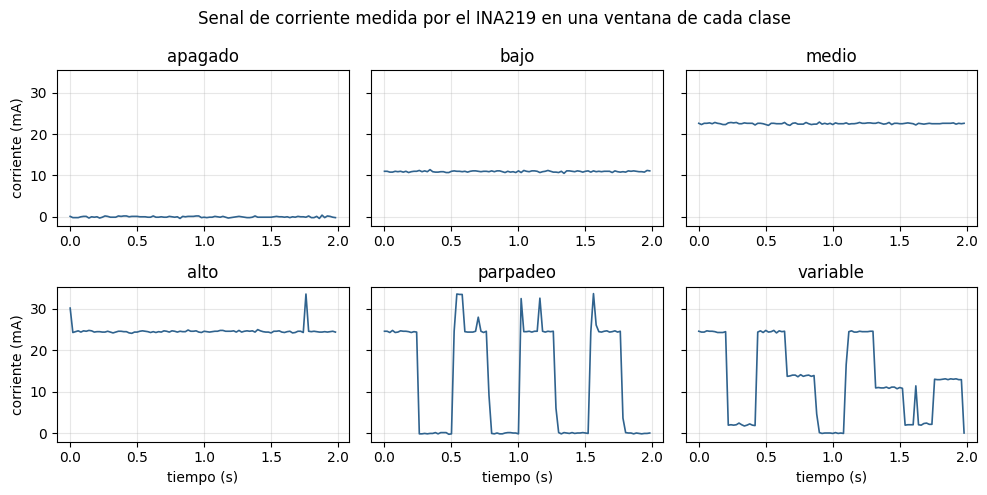

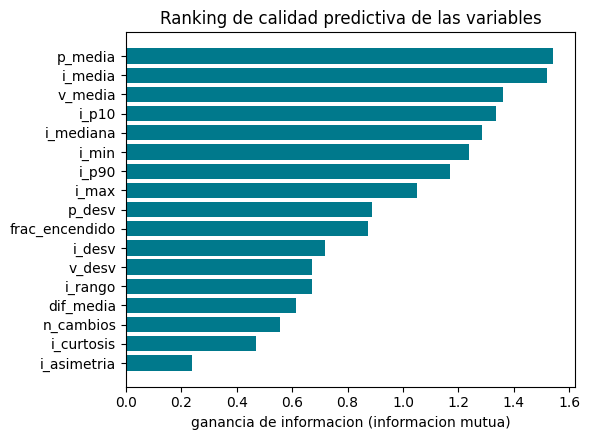

,clase,i_media_mean,i_media_std,i_desv_mean,i_desv_std,frac_encendido_mean,frac_encendido_std,n_cambios_mean,n_cambios_std
0,alto,33.459,1.261,0.215,0.335,1.000,0.000,0.060,0.258
1,apagado,-0.043,0.030,0.136,0.020,0.000,0.000,0.000,0.000
2,bajo,11.360,0.352,0.154,0.080,1.000,0.000,0.000,0.000
3,medio,22.561,0.323,0.165,0.130,1.000,0.000,0.010,0.100
4,parpadeo,12.012,5.538,10.879,4.330,0.537,0.115,2.265,1.039
5,variable,17.469,5.841,6.219,3.464,0.901,0.184,1.650,1.001


,variable,ganancia_informacion
15,p_media,1.543362
0,i_media,1.520598
13,v_media,1.360740
6,i_p10,1.335664
4,i_mediana,1.283682
2,i_min,1.240094
7,i_p90,1.169699
3,i_max,1.051360
16,p_desv,0.888300
10,frac_encendido,0.873441


In [8]:
ranking = describir(datos, variables)
display(pd.read_csv(TABLAS / "estadisticas_por_clase.csv"))
display(ranking)

## Paso 4. Modelado: Naive Bayes + 12 modelos

In [9]:
def construir_modelos():
    """Cada modelo va en un Pipeline con estandarizacion (los arboles no la necesitan,
    pero no les afecta) y una rejilla pequena de parametros para optimizar."""
    esc = lambda m: Pipeline([("escalador", StandardScaler()), ("modelo", m)])
    return {
        "Naive Bayes": (esc(GaussianNB()),
                        {"modelo__var_smoothing": [1e-9, 1e-6, 1e-3, 1e-1]}),
        "Regresion logistica": (esc(LogisticRegression(max_iter=5000)),
                                {"modelo__C": [0.1, 1, 10, 100]}),
        "k-NN": (esc(KNeighborsClassifier()),
                 {"modelo__n_neighbors": [1, 3, 5, 9, 15]}),
        "Arbol de decision": (esc(DecisionTreeClassifier(random_state=SEMILLA)),
                              {"modelo__max_depth": [2, 3, 5, 8, None]}),
        "Bosque aleatorio": (esc(RandomForestClassifier(random_state=SEMILLA)),
                             {"modelo__n_estimators": [100, 300],
                              "modelo__max_depth": [None, 5]}),
        "Extra Trees": (esc(ExtraTreesClassifier(random_state=SEMILLA)),
                        {"modelo__n_estimators": [100, 300],
                         "modelo__max_depth": [None, 5]}),
        "Gradient Boosting": (esc(GradientBoostingClassifier(random_state=SEMILLA)),
                              {"modelo__n_estimators": [100, 200],
                               "modelo__learning_rate": [0.05, 0.1]}),
        "Hist. Gradient Boosting": (esc(HistGradientBoostingClassifier(random_state=SEMILLA)),
                                    {"modelo__learning_rate": [0.05, 0.1],
                                     "modelo__max_depth": [None, 3]}),
        "AdaBoost": (esc(AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=2),
                                            random_state=SEMILLA)),
                     {"modelo__n_estimators": [50, 200],
                      "modelo__learning_rate": [0.5, 1.0]}),
        "SVM RBF": (esc(SVC(probability=True, random_state=SEMILLA)),
                    {"modelo__C": [0.1, 1, 10, 100], "modelo__gamma": ["scale", 0.01]}),
        "SVM lineal": (esc(CalibratedClassifierCV(LinearSVC(max_iter=20000))),
                       {"modelo__estimator__C": [0.01, 0.1, 1, 10]}),
        "LDA": (esc(LinearDiscriminantAnalysis()),
                {"modelo__solver": ["svd", "lsqr"]}),
        "Red neuronal MLP": (esc(MLPClassifier(max_iter=3000, random_state=SEMILLA)),
                             {"modelo__hidden_layer_sizes": [(16,), (32, 16)],
                              "modelo__alpha": [1e-4, 1e-2]}),
    }

## Pasos 5 y 6. Optimización de parámetros y evaluación

In [10]:
def dividir_capturas(datos):
    """70 % de las capturas para entrenar y 30 % para probar, estratificado por clase.
    Se divide por CAPTURA (no por ventana) para que no haya fuga de informacion."""
    capt = datos.groupby("captura")["clase"].first()
    c_tr, c_te = train_test_split(capt.index, test_size=0.3, stratify=capt.values,
                                  random_state=SEMILLA)
    return datos["captura"].isin(c_tr).to_numpy(), datos["captura"].isin(c_te).to_numpy()


def entrenar_y_evaluar(datos, variables):
    en_tr, en_te = dividir_capturas(datos)
    X, y, grupos = datos[variables].to_numpy(), datos["clase"].to_numpy(), datos["captura"].to_numpy()
    X_tr, y_tr, g_tr, X_te, y_te = X[en_tr], y[en_tr], grupos[en_tr], X[en_te], y[en_te]
    print(f"[4] Entrenamiento: {len(y_tr)} ventanas ({len(set(g_tr))} capturas) | "
          f"Prueba: {len(y_te)} ventanas ({len(set(grupos[en_te]))} capturas)")
    cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEMILLA)

    filas, ajustados = [], {}
    for nombre, (modelo, rejilla) in construir_modelos().items():
        busqueda = GridSearchCV(modelo, rejilla, cv=cv, scoring="balanced_accuracy", n_jobs=-1)
        busqueda.fit(X_tr, y_tr, groups=g_tr)
        mejor = busqueda.best_estimator_
        pred = mejor.predict(X_te)
        prob = mejor.predict_proba(X_te)
        filas.append({
            "modelo": nombre,
            "mejores_parametros": str({k.replace("modelo__", ""): v
                                       for k, v in busqueda.best_params_.items()}),
            "eb_validacion_cruzada": busqueda.best_score_,
            "exactitud_prueba": accuracy_score(y_te, pred),
            "eb_prueba": balanced_accuracy_score(y_te, pred),
            "f1_macro_prueba": f1_score(y_te, pred, average="macro"),
            "log_loss_prueba": log_loss(y_te, prob, labels=mejor.classes_),
        })
        ajustados[nombre] = mejor
        print(f"    {nombre:<24} EB validacion {busqueda.best_score_:.3f} | "
              f"EB prueba {filas[-1]['eb_prueba']:.3f}")

    tabla = pd.DataFrame(filas).sort_values(["eb_prueba", "log_loss_prueba"],
                                            ascending=[False, True])
    guardar_tabla(tabla, "comparacion_modelos.csv")
    return tabla, ajustados, X_te, y_te

In [11]:
tabla, ajustados, X_te, y_te = entrenar_y_evaluar(datos, variables)
display(tabla)

[4] Entrenamiento: 840 ventanas (210 capturas) | Prueba: 360 ventanas (90 capturas)


    Naive Bayes              EB validacion 0.926 | EB prueba 0.936


    Regresion logistica      EB validacion 0.952 | EB prueba 0.953


    k-NN                     EB validacion 0.936 | EB prueba 0.944
    Arbol de decision        EB validacion 0.929 | EB prueba 0.939


    Bosque aleatorio         EB validacion 0.944 | EB prueba 0.964


...

    AdaBoost                 EB validacion 0.919 | EB prueba 0.953


    SVM RBF                  EB validacion 0.948 | EB prueba 0.942


    SVM lineal               EB validacion 0.946 | EB prueba 0.942
    LDA                      EB validacion 0.932 | EB prueba 0.939


    Red neuronal MLP         EB validacion 0.950 | EB prueba 0.942


,modelo,mejores_parametros,eb_validacion_cruzada,exactitud_prueba,eb_prueba,f1_macro_prueba,log_loss_prueba
6,Gradient Boosting,"{'learning_rate': 0.05, 'n_estimators': 100}",0.941667,0.966667,0.966667,0.966530,0.105362
4,Bosque aleatorio,"{'max_depth': None, 'n_estimators': 100}",0.944048,0.963889,0.963889,0.963570,0.111386
7,Hist. Gradient Boosting,"{'learning_rate': 0.05, 'max_depth': 3}",0.954762,0.963889,0.963889,0.963842,0.111485
5,Extra Trees,"{'max_depth': None, 'n_estimators': 100}",0.951190,0.961111,0.961111,0.960466,0.212719
1,Regresion logistica,{'C': 100},0.952381,0.952778,0.952778,0.951506,0.121846
8,AdaBoost,"{'learning_rate': 0.5, 'n_estimators': 50}",0.919048,0.952778,0.952778,0.952558,1.710218
2,k-NN,{'n_neighbors': 5},0.935714,0.944444,0.944444,0.941500,0.988775
12,Red neuronal MLP,"{'alpha': 0.0001, 'hidden_layer_sizes': (16,)}",0.950000,0.941667,0.941667,0.939188,0.168620
9,SVM RBF,"{'C': 100, 'gamma': 0.01}",0.947619,0.941667,0.941667,0.938805,0.185455
10,SVM lineal,{'estimator__C': 10},0.946429,0.941667,0.941667,0.939475,0.373143


## Paso 7. Resultados: comparación de modelos y matrices de confusión

In [12]:
def figuras_resultados(tabla, ajustados, X_te, y_te):
    # Figura 3: exactitud balanceada en prueba de los 13 modelos
    t = tabla.iloc[::-1]
    colores = ["#d1495b" if m == "Naive Bayes" else "#30638e" for m in t["modelo"]]
    fig, ax = plt.subplots(figsize=(7, 5))
    ax.barh(t["modelo"], t["eb_prueba"], color=colores)
    for yy, v in enumerate(t["eb_prueba"]):
        ax.text(v + 0.005, yy, f"{v:.3f}", va="center", fontsize=8)
    ax.set_xlim(0, 1.08); ax.set_xlabel("exactitud balanceada en prueba")
    ax.set_title("Comparacion de modelos (Naive Bayes en rojo)")
    fig.tight_layout(); guardar_figura(fig, "fig03_comparacion_modelos.png")

    # Figura 4: matrices de confusion de Naive Bayes y del mejor modelo
    mejor = tabla.iloc[0]["modelo"] if tabla.iloc[0]["modelo"] != "Naive Bayes" \
        else tabla.iloc[1]["modelo"]
    fig, axs = plt.subplots(1, 2, figsize=(10, 4.3))
    for ax, nombre in zip(axs, ["Naive Bayes", mejor]):
        cm = confusion_matrix(y_te, ajustados[nombre].predict(X_te), labels=CLASES)
        ax.imshow(cm, cmap="Blues")
        for a in range(len(CLASES)):
            for b in range(len(CLASES)):
                ax.text(b, a, cm[a, b], ha="center", va="center",
                        color="white" if cm[a, b] > cm.max() / 2 else "black")
        ax.set_xticks(range(len(CLASES)), CLASES, rotation=35, ha="right")
        ax.set_yticks(range(len(CLASES)), CLASES)
        ax.set_xlabel("clase predicha"); ax.set_ylabel("clase real"); ax.set_title(nombre)
    fig.tight_layout(); guardar_figura(fig, "fig04_matrices_confusion.png")
    return mejor

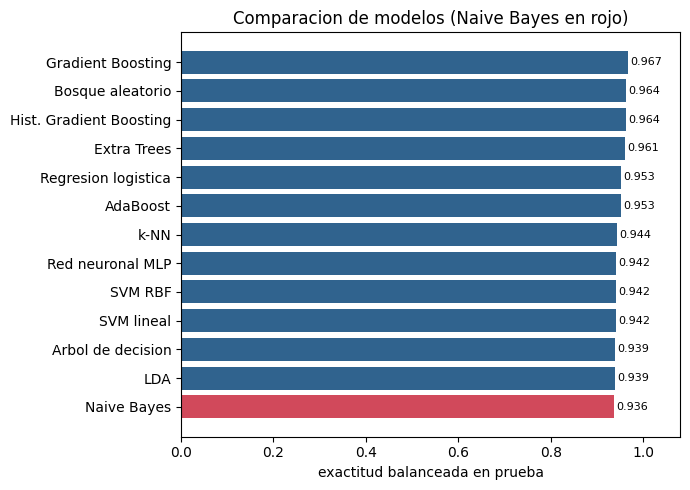

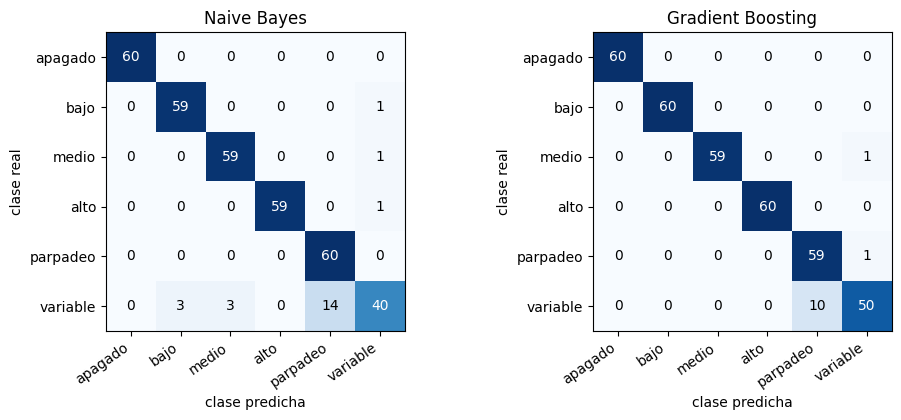

Mejor modelo: Gradient Boosting


In [13]:
mejor = figuras_resultados(tabla, ajustados, X_te, y_te)
print("Mejor modelo:", mejor)

## Paso 8. Análisis del largo de ventana

In [14]:
def analizar_largo_ventana(df, ajustados, mejor):
    """Repite la evaluacion en prueba con ventanas de 0,2 / 0,5 / 1 / 2 s, usando los
    parametros ya elegidos para Naive Bayes y para el mejor modelo."""
    filas = []
    for largo in LARGOS_ANALISIS_MS:
        datos = construir_dataset(df, largo, guardar=False)
        variables = [c for c in datos.columns if c not in ("captura", "clase")]
        en_tr, en_te = dividir_capturas(datos)
        X, y = datos[variables].to_numpy(), datos["clase"].to_numpy()
        for nombre in ["Naive Bayes", mejor]:
            m = clone(ajustados[nombre]).fit(X[en_tr], y[en_tr])
            filas.append({"largo_ms": largo, "modelo": nombre,
                          "eb_prueba": balanced_accuracy_score(y[en_te], m.predict(X[en_te]))})
    tabla = pd.DataFrame(filas)
    guardar_tabla(tabla, "largo_ventana.csv")

    fig, ax = plt.subplots(figsize=(6, 4))
    for nombre, color in [("Naive Bayes", "#d1495b"), (mejor, "#30638e")]:
        t = tabla[tabla["modelo"] == nombre]
        ax.plot(t["largo_ms"] / 1000, t["eb_prueba"], marker="o", color=color, label=nombre)
    ax.set_xlabel("largo de la ventana (s)"); ax.set_ylabel("exactitud balanceada en prueba")
    ax.set_title("Mientras mas larga la ventana, mas facil distinguir las clases")
    ax.grid(alpha=0.3); ax.legend()
    fig.tight_layout(); guardar_figura(fig, "fig05_largo_ventana.png")
    print("[6] Largo de ventana:")
    print(tabla.pivot(index="largo_ms", columns="modelo", values="eb_prueba").round(3).to_string())
    return tabla

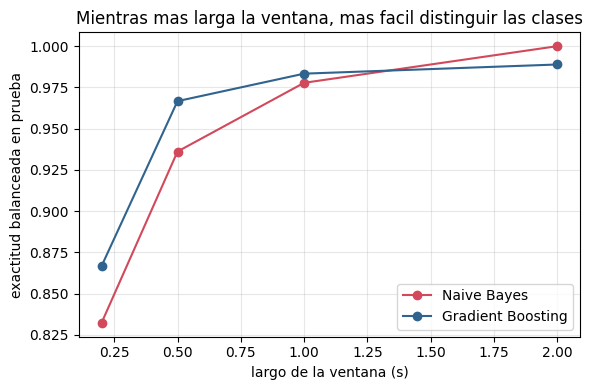

[6] Largo de ventana:
modelo    Gradient Boosting  Naive Bayes
largo_ms                                
200                   0.867        0.832
500                   0.967        0.936
1000                  0.983        0.978
2000                  0.989        1.000


modelo,Gradient Boosting,Naive Bayes
largo_ms,,
200,0.867,0.832
500,0.967,0.936
1000,0.983,0.978
2000,0.989,1.000


In [15]:
largo = analizar_largo_ventana(df, ajustados, mejor)
display(largo.pivot(index="largo_ms", columns="modelo", values="eb_prueba").round(3))

## Resumen

In [16]:
nb = tabla[tabla["modelo"] == "Naive Bayes"].iloc[0]
mb = tabla[tabla["modelo"] == mejor].iloc[0]
print(f"Naive Bayes:  EB prueba {nb['eb_prueba']:.3f} | F1 {nb['f1_macro_prueba']:.3f} | log loss {nb['log_loss_prueba']:.3f}")
print(f"Mejor modelo ({mejor}): EB prueba {mb['eb_prueba']:.3f} | F1 {mb['f1_macro_prueba']:.3f} | log loss {mb['log_loss_prueba']:.3f}")

Naive Bayes:  EB prueba 0.936 | F1 0.933 | log loss 1.439
Mejor modelo (Gradient Boosting): EB prueba 0.967 | F1 0.967 | log loss 0.105
